## Data

In [6]:
import pandas as pd
import numpy as np
data = pd.read_csv('titanic3.csv')

In [7]:
data = data.replace('?', np.nan)
data = data.astype({"age": np.float64, "fare": np.float64})

<Axes: xlabel='survived', ylabel='fare'>

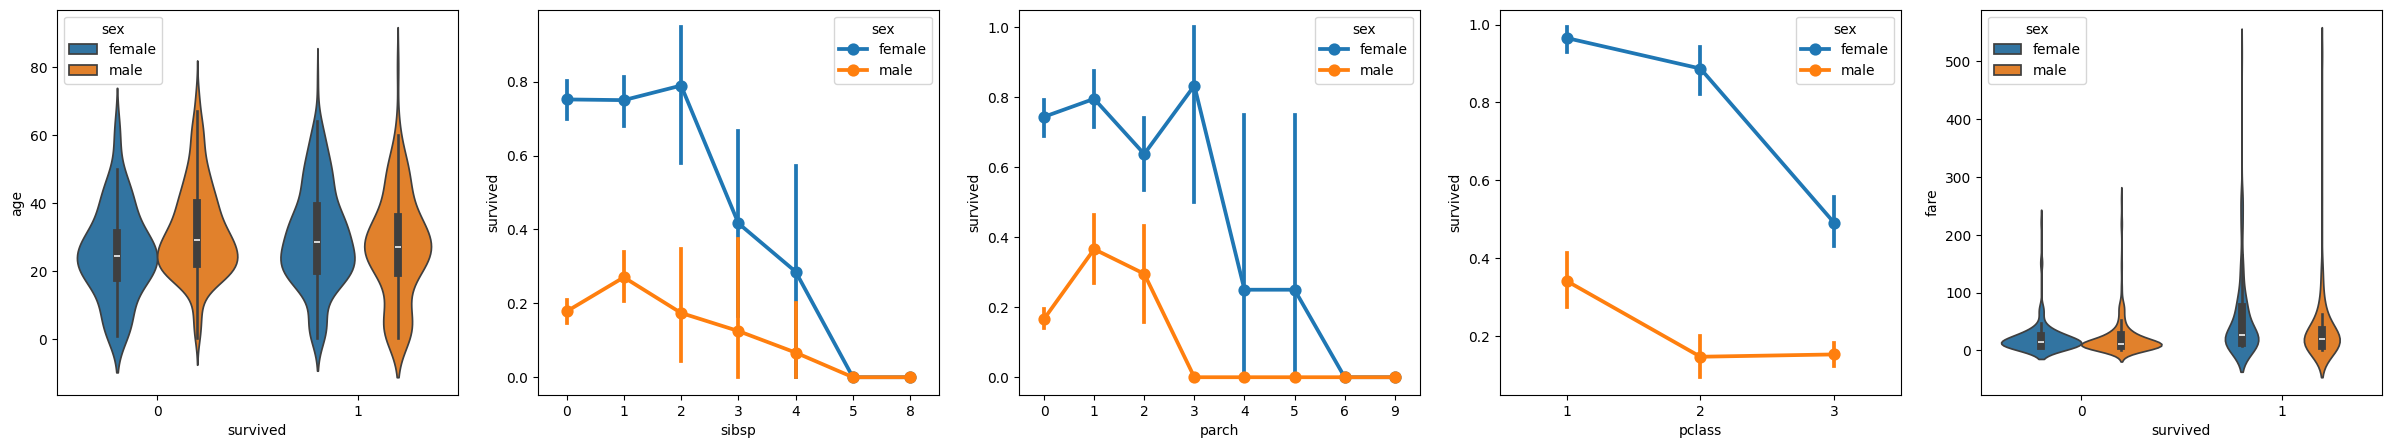

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axs = plt.subplots(ncols=5, figsize=(30,5))
sns.violinplot(x="survived", y="age", hue="sex", data=data, ax=axs[0])
sns.pointplot(x="sibsp", y="survived", hue="sex", data=data, ax=axs[1])
sns.pointplot(x="parch", y="survived", hue="sex", data=data, ax=axs[2])
sns.pointplot(x="pclass", y="survived", hue="sex", data=data, ax=axs[3])
sns.violinplot(x="survived", y="fare", hue="sex", data=data, ax=axs[4])


In [9]:
with pd.option_context("future.no_silent_downcasting", True):
    data = data.replace({'male': 1, 'female': 0}).infer_objects(copy=False)

In [10]:
data.corr(numeric_only=True).abs()[["survived"]]

,survived
pclass,0.312469
survived,1.000000
sex,0.528693
age,0.055512
sibsp,0.027825
parch,0.082660
fare,0.244265
body,NaN


In [11]:
data['relatives'] = data.apply (lambda row: int((row['sibsp'] + row['parch']) > 0), axis=1)
data.corr(numeric_only=True).abs()[["survived"]]

,survived
pclass,0.312469
survived,1.000000
sex,0.528693
age,0.055512
sibsp,0.027825
parch,0.082660
fare,0.244265
body,NaN
relatives,0.201719


In [12]:
data = data[['sex', 'pclass','age','relatives','fare','survived']].dropna()

## Traditional Model

In [13]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(data[['sex','pclass','age','relatives','fare']], data.survived, test_size=0.2, random_state=0)

In [14]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
# `fit_transform` used exclusively on the training dataset to learn the parameters and transform the data simultaneously.
X_train = sc.fit_transform(x_train)
# `transform` used on the test dataset to ensure consistency with the training data parameters and prevent data leakage.
X_test = sc.transform(x_test)

In [15]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [16]:
from sklearn import metrics
predict_test = model.predict(X_test)
print(metrics.accuracy_score(y_test, predict_test))

0.7464114832535885


## Neural Network

The first step is to import the required libraries and to create the model. In this case, you'll use a Sequential neural network, which is a layered neural network wherein there are multiple layers that feed into each other in sequence.

In [17]:
from keras.models import Sequential
from keras.layers import Dense

nmodel = Sequential()

After defining the model, the next step is to add the layers of the neural network. For now, let's keep things simple and just use three layers. Add the following code to create the layers of the neural network.

In [18]:
# The first layer will be set to have a dimension of 5, since you have five inputs: sex, pclass, age, relatives, and fare.
nmodel.add(Dense(5, kernel_initializer = 'uniform', activation = 'relu', input_dim = 5))
# The middle layer was kept at 5 for simplicity, although that value could have been different.
nmodel.add(Dense(5, kernel_initializer = 'uniform', activation = 'relu'))
# The last layer must output 1, since you want a 1-dimensional output indicating whether a passenger would survive.
nmodel.add(Dense(1, kernel_initializer = 'uniform', activation = 'sigmoid'))

/Users/a/code/jupyter-my-playground/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


The rectified linear unit (relu) activation function is used as a good general activation function for the first two layers, while the sigmoid activation function is required for the final layer as the output you want (of whether a passenger survives or not) needs to be scaled in the range of 0-1 (the probability of a passenger surviving).

In [19]:
nmodel.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66 (264.00 B)

 Trainable params: 66 (264.00 B)

 Non-trainable params: 0 (0.00 B)

Once the model is created, it needs to be compiled. As part of this, you need to define what type of optimizer will be used, how loss will be calculated, and what metric should be optimized for. Add the following code to build and train the model. You'll notice that after training, the accuracy is ~61%.

In [20]:
nmodel.compile(optimizer="adam", loss='binary_crossentropy', metrics=['accuracy'])
nmodel.fit(X_train, y_train, batch_size=32, epochs=50)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 791us/step - accuracy: 0.5825 - loss: 0.6924
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 786us/step - accuracy: 0.5861 - loss: 0.6905
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step - accuracy: 0.5861 - loss: 0.6884
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 704us/step - accuracy: 0.5861 - loss: 0.6852
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step - accuracy: 0.6388 - loss: 0.6804
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 647us/step - accuracy: 0.7620 - loss: 0.6735
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 659us/step - accuracy: 0.7799 - loss: 0.6643
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 633us/step - accuracy: 0.7763 - loss: 0.6520
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 633us/step - accuracy: 0.7727 - loss: 0.6376
Epoch 10/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 653us/step - accuracy: 0.7763 - loss: 0.6221
Epoch 11/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 625us/step - accuracy: 0.7739 - loss: 0.6076
Epoch 12/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 641us/step

In [23]:
y_pred = np.rint(nmodel.predict(X_test).flatten())
print(metrics.accuracy_score(y_test, y_pred))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
0.8038277511961722
